# Notebook maestro - De JSONLines a la submission

Instala las dependencias, audita los datos y ejecuta el pipeline completo en una sola corrida. round3 incluye LightGBM, especialistas, stacking, embeddings multilingues y, si estan instalados, MLP y TabNet. Las metricas locales y el score publico de Kaggle se reportan por separado.


## 1. Entorno y datos

Al ejecutar todas las celdas, el notebook instala los paquetes listados y entrena con los JSONLines completos. En Colab, clona el repo y proporciona AP2026Q2_DATA_DIR; en Windows se usa data/ap_2026_q_2/raw si existe. La descarga de pesos de texto se hace una vez y la inferencia corre en CPU.

Variables: AP_RUN_MODE=full (por defecto), AP_PIPELINE=round3, AP_MINUTES=90, AP_INSTALL_DEPS=1. Para revisar solo resultados existentes, define AP_RUN_MODE=report. No guardes tokens en el notebook.


In [ ]:
import os,sys,subprocess
INSTALL_DEPS=os.getenv('AP_INSTALL_DEPS','1' if os.getenv('AP_RUN_MODE','full')=='full' else '0')=='1'
if INSTALL_DEPS:
    for req in ['requirements_optimized.txt','requirements_round3.txt','requirements_deep.txt']:
        subprocess.check_call([sys.executable,'-m','pip','install','-r',req])


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,json
import numpy as np
import pandas as pd
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/competition_pipeline_v2.py').exists()),None)
if ROOT is None:raise RuntimeError('Abrir desde el repo tp_ap.')
sys.path.insert(0,str(ROOT/'src'))
DATA_DIR=Path(os.getenv('AP2026Q2_DATA_DIR',str(ROOT/'data/ap_2026_q_2/raw')))
PIPELINE=os.getenv('AP_PIPELINE','round3')
OUT=Path(os.getenv('AP_OUTPUT_DIR',str(ROOT/'results'/'round_v5' if PIPELINE=='round3' else ROOT/'results'/'round_v2')))
OUT.mkdir(parents=True,exist_ok=True)


## 2. Configuracion explicita

full ejecuta todo el entrenamiento; report abre resultados existentes. round3 usa splits agrupados (seed 42 para seleccion, 731 para confirmacion), limita el tiempo total y reserva tiempo para confirmar y refitear una mejora. El pipeline prueba MLP y TabNet cuando estan disponibles.


In [2]:
RUN_MODE=os.getenv('AP_RUN_MODE','full')
ALLOW_PARTIAL=os.getenv('AP_ALLOW_PARTIAL','0')=='1'
MINUTES=float(os.getenv('AP_MINUTES','90'))
TRIALS=int(os.getenv('AP_TRIALS','24'))
print({'modo':RUN_MODE,'pipeline':PIPELINE,'datos':str(DATA_DIR),'output':str(OUT),'parcial':ALLOW_PARTIAL,'minutos':MINUTES,'ensayos':TRIALS,'python':sys.version.split()[0]})


{'modo': 'report', 'datos': '/workspace/scratch/d7363d2f086f/repo/data/ap_2026_q_2/raw', 'output': '/workspace/scratch/d7363d2f086f/repo/results/round_v3', 'parcial': False, 'minutos': 90.0, 'ensayos': 24}


## 3. Auditoría
Número de filas, JSON válido, etiquetas, hash SHA-256 y ausencia de target en test. No se omiten filas inválidas silenciosamente.
Una primera copia local resultó incompleta durante la sesión; la copia recuperada del ZIP pasó la auditoría con 70.000 y 30.000 filas. La auditoría siguiente, no esa incidencia del entorno, decide qué datos pueden usarse.

In [3]:
if RUN_MODE=='report':
    audit=json.loads((OUT/'data_audit.json').read_text())
    display(pd.DataFrame(audit))
    print('Auditoría histórica guardada; no se vuelven a leer datos en report.')
else:
    from competition_pipeline_v2 import load_data,groups_for
    from optimize_leaderboard import split
    train,test,audit=load_data(DATA_DIR,OUT,ALLOW_PARTIAL)
    display(pd.DataFrame(audit));display(train[['id','title','condition','price','category_id']].head())


Auditoría histórica guardada; no se vuelven a leer datos en report.


,filename,expected_rows,valid_rows,invalid_lines,sha256,complete
0,train_data.jsonlines,70000,70000,[],aa49b8710d06f666eeb3cf65c256c8c4f90bf4dbb22c69...,True
1,test_data.jsonlines,30000,30000,[],05921bd73deba1c4ed5a4d564e0351729eae8f2ef197bc...,True


## 4. Split por familia y baseline
Cada `parent_item_id` identifica una familia que permanece en un solo lado del split. Si falta, la clave individual incluye el ID de fila. El mismo vendedor puede estar en ambos lados; no evaluamos aquí vendedores totalmente nuevos.
Nueva ronda: 80/20, semilla 42; comprobación: 80/20, semilla 731. El histórico de selección usó 70/30.

In [4]:
if RUN_MODE=='report':
    protocol=json.loads((OUT/'run_manifest.json').read_text())
    display(protocol['selection']);display(protocol['confirmation'])
    print('Protocolos históricos. La comprobación por familias se realiza al entrenar.')
else:
    y=(train.condition=='used').to_numpy(dtype='int8');groups=groups_for(train)
    t,v=split(y,groups,42,2)
    assert not set(groups[t])&set(groups[v])
    print({'desarrollo':len(t),'validacion':len(v),'familias_compartidas':0})


Protocolos históricos. La comprobación por familias se realiza al entrenar.


{'seed': 42, 'holdout_folds': 2, 'train_rows': 56000, 'validation_rows': 14000}

{'seed': 731,
 'holdout_folds': 2,
 'train_rows': 56000,
 'validation_rows': 14000}

## 5. Variables y protección contra fuga
| Bloque | Construcción | Dónde aprende |
|---|---|---|
| JSON anidado | Logística, variantes, pagos, fotos, atributos | Parseo fila a fila |
| Atributos | Hasta 250 frecuentes, excluyendo condición explícita | IDs elegidos en desarrollo |
| Texto | Palabras, caracteres, TF-IDF, SVD de 96 componentes | Desarrollo |
| Contexto | Precio relativo y frecuencia por categoría/vendedor | Desarrollo, sin etiquetas |
| Tasas | Vendedor, categoría y combinaciones | OOF interno por familia |
| SVM | Predicciones de texto como otra columna | OOF, con vocabulario refiteado en cada fold |
| Boosting | LightGBM y mezcla de sus configuraciones | Selección y posterior refit |
Las variables describen publicaciones existentes. Cantidades vendidas, estado o fechas posteriores no serían válidos para prometer predicción al crear la publicación. No afirmamos resolver ese escenario temporal distinto.

## 6. Ejecutar el ciclo completo

Ejecuta esta celda una vez. El orquestador reutiliza caches compatibles, reconstruye lo faltante, prueba las familias de modelos y evalua la seleccion en seed 731. Las dependencias deep learning se instalan en la celda inicial. Los pixeles de fotos solo se usan si las URLs responden; se conservan metadatos visuales cuando el servidor deniega acceso. El estado final queda en master_execution.json. La confirmacion usa otra particion del mismo dataset y no es un test ciego independiente.


In [5]:
import subprocess,time
if RUN_MODE=='full':
    if ALLOW_PARTIAL:raise ValueError('El maestro requiere 70.000 filas completas.')
    if PIPELINE=='round3':
        command=[sys.executable,'-u',str(ROOT/'src/run_round3.py'),'--data-dir',str(DATA_DIR),'--output',str(OUT),'--minutes',str(MINUTES),'--trials',str(min(TRIALS,12))]
    elif PIPELINE=='v2':
        command=[sys.executable,'-u',str(ROOT/'src/competition_pipeline_v2.py'),'--data-dir',str(DATA_DIR),'--output',str(OUT),'--trials',str(TRIALS)]
    else:raise ValueError('PIPELINE debe ser round3 o v2')
    log_path=OUT/'master_run.log';env=os.environ.copy();env.update(OPENBLAS_NUM_THREADS='2',OMP_NUM_THREADS='2',MKL_NUM_THREADS='2')
    with log_path.open('w',encoding='utf-8') as log:
        process=subprocess.Popen(command,cwd=ROOT,env=env,stdout=log,stderr=subprocess.STDOUT)
        try:returncode=process.wait(timeout=MINUTES*60+30)
        except subprocess.TimeoutExpired:
            process.terminate()
            try:process.wait(timeout=10)
            except subprocess.TimeoutExpired:process.kill();process.wait()
            returncode=124
    print('returncode',returncode,'log',log_path)
    print(log_path.read_text(encoding='utf-8',errors='replace')[-12000:])
    if returncode:print('Inspect incomplete_stages in master_execution.json.')


Modo reporte: se leen resultados existentes, no se entrena.


## 7. Resultados comparables
Accuracy cuenta aciertos; balanced accuracy da igual peso a las clases; macro F1 resume precisión y recall; log loss evalúa probabilidades. El umbral elegido queda asociado al candidato.
Para hablar de avance hacia 95%, el train debe estar completo y la comprobación congelada debe sostenerlo. Un score de selección mayor por sí solo no basta.

Confirmación congelada todavía pendiente.


,name,family,accuracy,threshold
25,combined_normstack_0,combined,0.940571,0.525
31,combined_normstack_6,combined,0.940571,0.535
27,combined_normstack_2,combined,0.940500,0.500
33,combined_normstack_8,combined,0.940500,0.510
34,combined_normstack_9,combined,0.940500,0.515
26,combined_normstack_1,combined,0.940429,0.530
32,combined_normstack_7,combined,0.940357,0.505
35,combined_normstack_10,combined,0.940357,0.465
39,combined_stackbase_2,combined,0.940357,0.485
41,normalize_lgb_domain_1,normalize,0.940357,0.465


{'names': ['category_cluster_8_w0.5', 'prior_ensemble'],
 'weights': [0.5, 0.5],
 'accuracy': 0.9407142857142857,
 'balanced_accuracy': 0.941610257771557,
 'macro_f1': 0.9405171315677712,
 'logloss': 0.1535776356131038,
 'threshold': 0.48,
 'components': [{'name': 'category_cluster_8_w0.5',
   'accuracy': 0.9396428571428571,
   'balanced_accuracy': 0.9399217256554033,
   'macro_f1': 0.9393805105287316,
   'logloss': 0.1558949153837418,
   'threshold': 0.54,
   'seconds': 112.168859752,
   'feature_set': 'category_experts',
   'global_params': {'n_estimators': 449,
    'learning_rate': 0.021945374001337975,
    'num_leaves': 106,
    'min_child_samples': 88,
    'reg_lambda': 0.333913107651493,
    'colsample_bytree': 0.696858079929112,
    'subsample': 0.9,
    'subsample_freq': 1,
    'cat_smooth': 26.956368354888806,
    'max_cat_threshold': 8,
    'n_jobs': 2,
    'verbosity': -1,
    'random_state': 2026,
    'reg_alpha': 0.3891178604095862},
   'expert_weight': 0.5,
   'covered_fr

None

{'status': 'interrupted_closed_from_durable_checkpoint',
 'original_deadline_utc': '2026-10-11T00:43:51.416Z',
 'closed_utc': '2026-10-11T01:03:53.263822+00:00',
 'last_durable_commit': 'c3eb04b92633d7c66401eff4f04435ac80085fd4',
 'completed_configurations_with_saved_metrics': 57,
 'best_by_family': [{'family': 'stacking',
   'name': 'stacking_base_lgb_structured_rates',
   'accuracy': 0.9386428571428572},
  {'family': 'category',
   'name': 'category_cluster_8_w0.5',
   'accuracy': 0.9396428571428572},
  {'family': 'normalize',
   'name': 'normalize_lgb_domain_1',
   'accuracy': 0.9403571428571428},
  {'family': 'combined',
   'name': 'combined_normstack_6',
   'accuracy': 0.9405714285714286}],
 'stacking_confirmation': {'accuracy': 0.9401428571428572,
  'balanced_accuracy': 0.9403872750036342,
  'macro_f1': 0.9398786964045123,
  'logloss': 0.16930350287289656,
  'threshold': 0.46},
 'prior_confirmation_accuracy': 0.9421428571428572,
 'public_reference_user_report': 0.94428,
 'goal_me

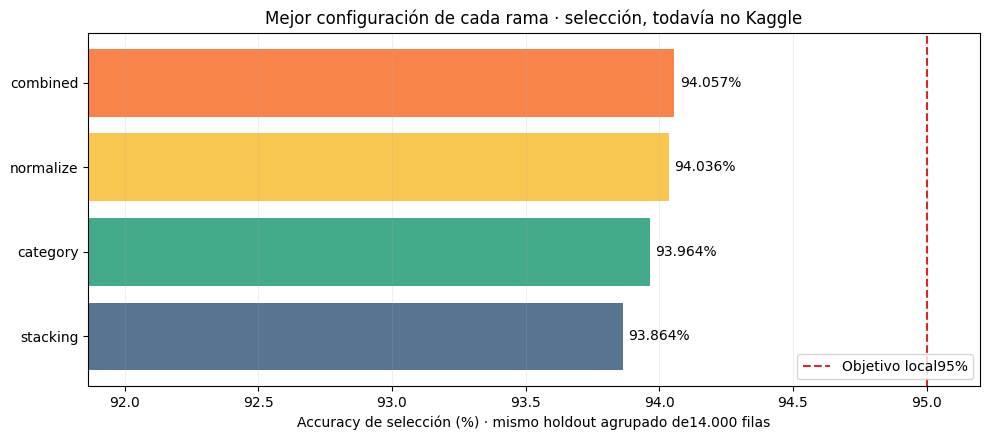

In [6]:
if PIPELINE=='round3':
    from round3_visuals import summarize,overview,frozen_evaluation
    results=summarize(OUT);display(results[[c for c in ['name','family','accuracy','threshold'] if c in results]].head(15))
    overview(OUT)
    if (OUT/'round3_selected.json').exists():
        selected=json.loads((OUT/'round3_selected.json').read_text());display(selected)
    display(frozen_evaluation(OUT))
else:
    if (OUT/'metrics.csv').exists():display(pd.read_csv(OUT/'metrics.csv').sort_values('accuracy',ascending=False))
    if (OUT/'selected.json').exists():display(json.loads((OUT/'selected.json').read_text()))
    from case_visuals import style,new_results,importance
    style();new_results(OUT);importance(OUT)

if (OUT/'closure.json').exists():display(json.loads((OUT/'closure.json').read_text()))

## 8. Submission

La referencia pública comprobada sigue identificada por separado. Un CSV nuevo solo se propone si tiene confirmación local; su puntaje de Kaggle queda pendiente hasta que se lo evalúe en la competencia. El refit usa todas las filas etiquetadas y transforma el test con lo aprendido en entrenamiento.

In [7]:
candidate=ROOT/'submissions/submission_optimized_ensemble.csv'
if PIPELINE=='round3' and (OUT/'round3_selected.json').exists():
    state=json.loads((OUT/'round3_selected.json').read_text())
    if state.get('promote_over_previous') and (OUT/'submission_round3.csv').exists():
        candidate=OUT/'submission_round3.csv';print('CSV experimental confirmado localmente; Kaggle pendiente.')
sub=pd.read_csv(candidate)
assert list(sub.columns)==['ID','condition'] and len(sub)==30000
assert sub.ID.tolist()==list(range(1,30001)) and set(sub.condition)<={'new','used'} and not sub.isna().any().any()
display(sub.head());print(candidate)
print('Referencia pública informada por el usuario:94.428%.')


/workspace/scratch/d7363d2f086f/repo/submissions/submission_optimized_ensemble.csv
Referencia pública informada por el usuario:94.428%.


,ID,condition
0,1,used
1,2,new
2,3,used
3,4,used
4,5,new


## 9. Trazabilidad

Se guardan auditoria, hashes, metricas, hiperparametros, filas de validacion, probabilidades, logs y submission. Pesos y caches regenerables quedan fuera de Git. El score publico historico informado es 94,428%; una ejecucion local no determina el score de Kaggle. Si no hay mejora confirmada, se conserva la mejor submission previa.
